# LAB 10 — K-Means Clustering

## Student Information
**Name:** Muhammad Umar  
**Student ID:** 023-24-0260  
**Section:** H  
**GitHub:**  
**Kaggle:**  

**Dataset:** Mall Customers (Kaggle) + Wine (UCI)  
**Dataset Source:**  
- https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python  
- https://archive.ics.uci.edu/dataset/109/wine  

**Random seed:** 42

This notebook follows the order and task numbering of the supplied Lab 10 manual. Each task includes its code, results, plots, and a short interpretation.

## Imports and Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Part 0 — Setup and First Look

## Task 0.1 — Load and check the data

In [2]:
data_path = r"C:\Users\umarc\Desktop\ML-Lab Practice\Mall_Customers.csv"

if not os.path.exists(data_path):
    data_path = "Mall_Customers.csv"

if not os.path.exists(data_path):
    data_path = "/mnt/data/Mall_Customers.csv"

df = pd.read_csv(data_path)
df = df.rename(columns={
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Spending"
})

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nGender counts:")
print(df["Gender"].value_counts())
print("\nDescriptive statistics:")
display(df[["Age", "Income", "Spending"]].describe())

Dataset shape: (200, 5)

Missing values:
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

Duplicate rows: 0

Gender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64

Descriptive statistics:


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


**Interpretation:** The Mall Customers dataset contains 200 customer records and 5 columns. The checks above show whether any values are missing or rows are duplicated, and the Gender counts show the category distribution. The descriptive-statistics table summarizes the age, income and spending-score ranges.

## Task 0.2 — Look at the data before clustering

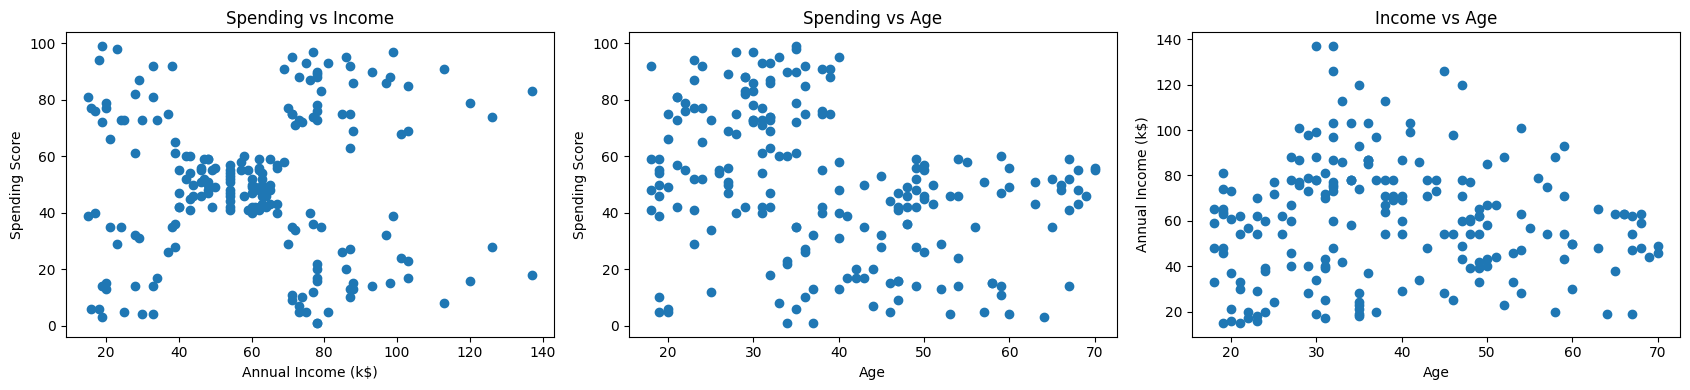

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].scatter(df["Income"], df["Spending"])
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score")
axes[0].set_title("Spending vs Income")

axes[1].scatter(df["Age"], df["Spending"])
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Spending Score")
axes[1].set_title("Spending vs Age")

axes[2].scatter(df["Age"], df["Income"])
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Annual Income (k$)")
axes[2].set_title("Income vs Age")

plt.tight_layout()
plt.show()

In [4]:
print("Question (a): The Income vs Spending plot shows the clearest visible groups. The other two plots show weaker separation.")
print("Question (b): Clustering has no target column containing correct answers. Therefore, accuracy and a train/test split are not suitable. We evaluate clusters using distances, silhouette, plots and domain understanding.")

Question (a): The Income vs Spending plot shows the clearest visible groups. The other two plots show weaker separation.
Question (b): Clustering has no target column containing correct answers. Therefore, accuracy and a train/test split are not suitable. We evaluate clusters using distances, silhouette, plots and domain understanding.


# Part 1 — K-Means From Scratch

## Task 1.1 — Lecture Example 1 in code (one feature)

In [5]:
x1 = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
centroids1 = np.array([4.0, 11.0])

iteration = 0

while True:
    distances = np.abs(x1[:, None] - centroids1[None, :])
    labels1 = distances.argmin(axis=1)
    new_centroids1 = centroids1.copy()

    for k in range(2):
        if np.any(labels1 == k):
            new_centroids1[k] = x1[labels1 == k].mean()

    iteration += 1
    print("Iteration:", iteration)
    print("Cluster 1:", x1[labels1 == 0])
    print("Cluster 2:", x1[labels1 == 1])
    print("New centroids:", new_centroids1)

    if np.allclose(new_centroids1, centroids1):
        centroids1 = new_centroids1
        break

    centroids1 = new_centroids1

inertia1 = ((x1 - centroids1[labels1]) ** 2).sum()
print("Final centroids:", centroids1)
print("Final inertia:", inertia1)

Iteration: 1
Cluster 1: [2. 4. 3.]
Cluster 2: [10. 12. 20. 30. 11. 25.]
New centroids: [ 3. 18.]
Iteration: 2
Cluster 1: [ 2.  4. 10.  3.]
Cluster 2: [12. 20. 30. 11. 25.]
New centroids: [ 4.75 19.6 ]
Iteration: 3
Cluster 1: [ 2.  4. 10. 12.  3. 11.]
Cluster 2: [20. 30. 25.]
New centroids: [ 7. 25.]
Iteration: 4
Cluster 1: [ 2.  4. 10. 12.  3. 11.]
Cluster 2: [20. 30. 25.]
New centroids: [ 7. 25.]
Final centroids: [ 7. 25.]
Final inertia: 150.0


**Interpretation:** The final centroids are 7 and 25, and the inertia is 150. These values match the lecture example. The loop stops when the centroids no longer change.

## Task 1.2 — Lecture Example 2 in code (two features)

In [6]:
points = np.array([
    [185, 72],
    [170, 56],
    [168, 60],
    [179, 68],
    [182, 72],
    [188, 77]
], dtype=float)

centroids2 = points[[0, 1]].copy()
iteration = 0

while True:
    distance_table = np.sqrt(((points[:, None, :] - centroids2[None, :, :]) ** 2).sum(axis=2))
    labels2 = distance_table.argmin(axis=1)
    new_centroids2 = centroids2.copy()

    for k in range(2):
        if np.any(labels2 == k):
            new_centroids2[k] = points[labels2 == k].mean(axis=0)

    iteration += 1
    print("Iteration:", iteration)
    print("Cluster 1:", np.where(labels2 == 0)[0] + 1)
    print("Cluster 2:", np.where(labels2 == 1)[0] + 1)
    print("New centroids:\n", new_centroids2)

    if np.allclose(new_centroids2, centroids2):
        centroids2 = new_centroids2
        break

    centroids2 = new_centroids2

final_distances2 = np.sqrt(((points[:, None, :] - centroids2[None, :, :]) ** 2).sum(axis=2))
distance_table_first = np.sqrt(((points[:, None, :] - points[[0, 1]][None, :, :]) ** 2).sum(axis=2))

print("Final distance table:\n", final_distances2)
print("First-iteration distance d(P3, M2):", distance_table_first[2, 1])
print("Final centroids:\n", centroids2)

Iteration: 1
Cluster 1: [1 4 5 6]
Cluster 2: [2 3]
New centroids:
 [[183.5   72.25]
 [169.    58.  ]]
Iteration: 2
Cluster 1: [1 4 5 6]
Cluster 2: [2 3]
New centroids:
 [[183.5   72.25]
 [169.    58.  ]]
Final distance table:
 [[ 1.52069063 21.26029163]
 [21.12610944  2.23606798]
 [19.7563281   2.23606798]
 [ 6.1897092  14.14213562]
 [ 1.52069063 19.10497317]
 [ 6.54312616 26.87005769]]
First-iteration distance d(P3, M2): 4.47213595499958
Final centroids:
 [[183.5   72.25]
 [169.    58.  ]]


**Interpretation:** Euclidean distance is used because each customer point has two numeric features: height and weight. The first-iteration distance from P3 to M2 is approximately 4.47, matching the lecture value.

## Task 1.3 — Write your own K-Means function

The function below does not call `KMeans`. It uses NumPy distances, nearest-centroid assignment, centroid updates and a convergence check. If a cluster becomes empty, its old centroid is kept.

In [7]:
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.array(X, dtype=float)
    centroids = np.array(init_centroids, dtype=float).copy()

    for iteration in range(1, max_iter + 1):
        distances = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
        labels = distances.argmin(axis=1)
        new_centroids = centroids.copy()

        for k in range(len(centroids)):
            if np.any(labels == k):
                new_centroids[k] = X[labels == k].mean(axis=0)

        if np.allclose(new_centroids, centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
    labels = distances.argmin(axis=1)
    inertia = ((X - centroids[labels]) ** 2).sum()

    return labels, centroids, inertia, iteration


labels_test, centers_test, inertia_test, iterations_test = my_kmeans(
    x1.reshape(-1, 1), np.array([[4.0], [11.0]])
)

print("Final clusters:")
for k in range(2):
    print("Cluster", k, ":", x1[labels_test == k])
print("Centroids:", centers_test.ravel())
print("Inertia:", inertia_test)
print("Iterations:", iterations_test)

Final clusters:
Cluster 0 : [ 2.  4. 10. 12.  3. 11.]
Cluster 1 : [20. 30. 25.]
Centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


**Interpretation:** The custom function returns four required values: cluster labels, final centroids, inertia and iteration count. On Lecture Example 1 it gives centroids 7 and 25 and inertia 150, so the manual implementation reproduces the expected result.

## Task 1.4 — Check your function against scikit-learn

In [8]:
X2 = df[["Income", "Spending"]].values
initial_rows = X2[:5].copy()

my_labels, my_centers, my_inertia, my_iterations = my_kmeans(X2, initial_rows)

sk_model = KMeans(
    n_clusters=5,
    init=initial_rows,
    n_init=1,
    tol=0,
    algorithm="lloyd",
    random_state=SEED
)
sk_model.fit(X2)

print("My K-Means iterations:", my_iterations)
print("sklearn iterations:", sk_model.n_iter_)
print("My inertia:", my_inertia)
print("sklearn inertia:", sk_model.inertia_)
print("Adjusted Rand Index between labels:", adjusted_rand_score(my_labels, sk_model.labels_))
print("My centroids:\n", my_centers)
print("sklearn centroids:\n", sk_model.cluster_centers_)
print("Centroids match:", np.allclose(my_centers, sk_model.cluster_centers_))

My K-Means iterations: 4
sklearn iterations: 4
My inertia: 44448.45544793371
sklearn inertia: 44448.45544793371
Adjusted Rand Index between labels: 1.0
My centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]
sklearn centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]
Centroids match: True


**Interpretation:** The inertia and centroids should match when both implementations use the same initial centroids and Lloyd updates. Adjusted Rand Index (ARI) checks whether the group assignments match while ignoring arbitrary cluster-number labels. A score of 1 means the two groupings are identical.

### Part 1 — Questions

In [9]:
print("1(a): Point 10 moves because after the first centroid update, its distance to the updated centroid of Cluster 1 becomes smaller than its distance to the updated centroid of Cluster 2.")
print("1(b): The loop stops when centroids stop changing. Each assignment/update step does not increase the K-Means objective, so it converges to a local minimum, but not necessarily the global best solution.")
print("1(c): Compare the printed inertia, centroids and ARI above. Small label-number differences are not meaningful because cluster labels are arbitrary.")
print("1(d): A centroid is the mean position of the customers in a cluster. K-Means needs numeric features because it calculates means and distances.")

1(a): Point 10 moves because after the first centroid update, its distance to the updated centroid of Cluster 1 becomes smaller than its distance to the updated centroid of Cluster 2.
1(b): The loop stops when centroids stop changing. Each assignment/update step does not increase the K-Means objective, so it converges to a local minimum, but not necessarily the global best solution.
1(c): Compare the printed inertia, centroids and ARI above. Small label-number differences are not meaningful because cluster labels are arbitrary.
1(d): A centroid is the mean position of the customers in a cluster. K-Means needs numeric features because it calculates means and distances.


# Part 2 — Choosing K: Elbow and Silhouette

## Task 2.1 — Elbow and silhouette for K = 2 to 10

,K,Inertia,Silhouette
0,2,181363.595960,0.296897
1,3,106348.373062,0.467614
2,4,73679.789039,0.493196
3,5,44448.455448,0.553932
4,6,37233.814511,0.539761
5,7,30241.343618,0.528810
6,8,25036.417604,0.454812
7,9,21916.794790,0.456109
8,10,20072.070939,0.441057


K with highest silhouette: 5


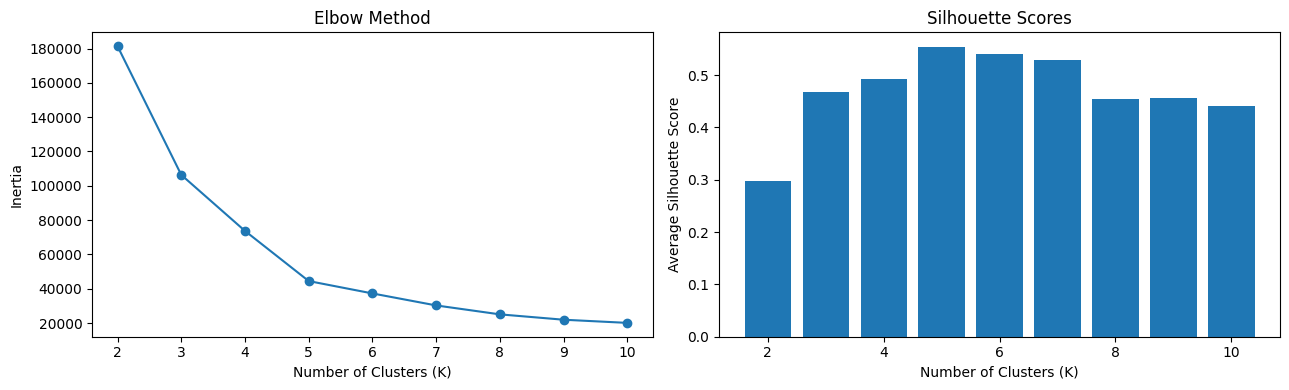

In [10]:
results_k = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = model.fit_predict(X2)
    results_k.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X2, labels)
    })

k_results = pd.DataFrame(results_k)
display(k_results)

best_silhouette_k = int(k_results.loc[k_results["Silhouette"].idxmax(), "K"])
print("K with highest silhouette:", best_silhouette_k)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_results["K"], k_results["Inertia"], marker="o")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")

axes[1].bar(k_results["K"], k_results["Silhouette"])
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Average Silhouette Score")
axes[1].set_title("Silhouette Scores")

plt.tight_layout()
plt.show()

**Interpretation:** Inertia decreases as K increases, so the elbow is the point after which the reduction becomes smaller. The silhouette table provides a second measure of cluster separation. The highest silhouette K is printed above. K should be selected by considering both plots and whether the groups make practical sense.

## Task 2.2 — Silhouette by hand

In [11]:
k5_model = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels_k5 = k5_model.fit_predict(X2)
all_distances = np.sqrt(((X2[:, None, :] - X2[None, :, :]) ** 2).sum(axis=2))

def silhouette_by_hand(X, labels, row):
    distances = np.sqrt(((X - X[row]) ** 2).sum(axis=1))
    own_cluster = labels[row]
    same = (labels == own_cluster)
    same[row] = False

    if same.sum() == 0:
        return 0.0, np.nan, 0.0

    a = distances[same].mean()
    other_means = []

    for cluster in np.unique(labels):
        if cluster != own_cluster:
            other_means.append(distances[labels == cluster].mean())

    b = min(other_means)
    s = (b - a) / max(a, b)
    return a, b, s

a0, b0, s0 = silhouette_by_hand(X2, labels_k5, 0)
library_s0 = silhouette_samples(X2, labels_k5)[0]

print("Customer 1 a:", a0)
print("Customer 1 b:", b0)
print("Customer 1 silhouette by hand:", s0)
print("Customer 1 silhouette from sklearn:", library_s0)

sil_values = silhouette_samples(X2, labels_k5)
cluster_silhouette = []

for cluster in np.unique(labels_k5):
    values = sil_values[labels_k5 == cluster]
    cluster_silhouette.append({
        "Cluster": cluster,
        "Count": len(values),
        "Mean Silhouette": values.mean(),
        "Minimum Silhouette": values.min()
    })

display(pd.DataFrame(cluster_silhouette))
print("Customers with negative silhouette:", int((sil_values < 0).sum()))

Customer 1 a: 24.64044215163639
Customer 1 b: 42.26526678748377
Customer 1 silhouette by hand: 0.41700493041881637
Customer 1 silhouette from sklearn: 0.4170049304188163


,Cluster,Count,Mean Silhouette,Minimum Silhouette
0,0,81,0.596651,0.115294
1,1,39,0.509171,0.225413
2,2,22,0.599013,0.050721
3,3,35,0.503987,-0.023381
4,4,23,0.512268,-0.009278


Customers with negative silhouette: 2


**Interpretation:** The hand-calculated silhouette for customer 1 should be the same as the scikit-learn value, apart from tiny floating-point rounding. A positive score means the customer is closer to its own cluster than to the nearest other cluster; a negative score suggests a possible poor assignment.

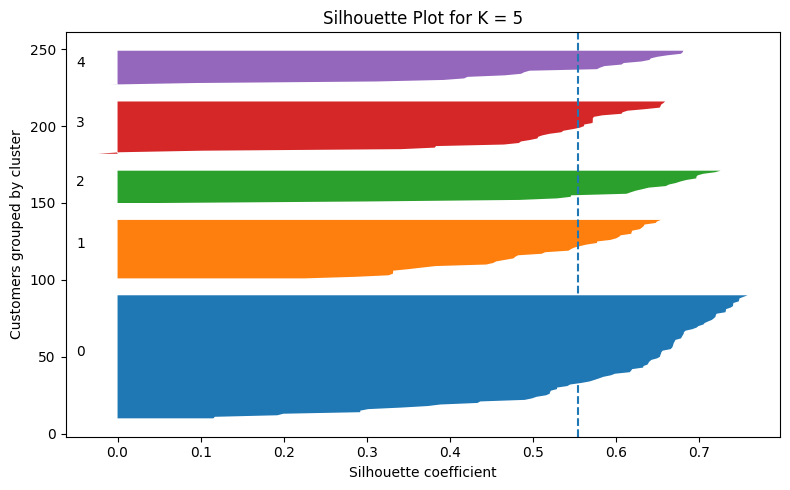

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10

for cluster in np.unique(labels_k5):
    values = np.sort(sil_values[labels_k5 == cluster])
    size = len(values)
    y_upper = y_lower + size
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, values)
    ax.text(-0.05, y_lower + size / 2, str(cluster))
    y_lower = y_upper + 10

ax.axvline(silhouette_score(X2, labels_k5), linestyle="--")
ax.set_xlabel("Silhouette coefficient")
ax.set_ylabel("Customers grouped by cluster")
ax.set_title("Silhouette Plot for K = 5")
plt.tight_layout()
plt.show()

**Interpretation:** Wider positive bands indicate customers that fit their assigned clusters more clearly. Points near zero are close to a cluster boundary, while negative values indicate customers that may fit another cluster better.

## Task 2.3 — The lecture practice problem

In [13]:
practice = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float).reshape(-1, 1)
practice_init = np.array([[1.0], [11.0]])

practice_labels, practice_centers, practice_inertia, practice_iterations = my_kmeans(
    practice, practice_init
)

print("Final clusters:")
for k in range(2):
    print("Cluster", k, ":", practice.ravel()[practice_labels == k])
print("Final centroids:", practice_centers.ravel())
print("Iterations:", practice_iterations)
print("Inertia:", practice_inertia)

practice_sil = silhouette_samples(practice, practice_labels)

for point in [1, 7, 11]:
    row = int(np.where(practice.ravel() == point)[0][0])
    a, b, s = silhouette_by_hand(practice, practice_labels, row)
    print("Point", point, "a =", a, "b =", b, "hand silhouette =", s,
          "sklearn silhouette =", practice_sil[row])

Final clusters:
Cluster 0 : [1. 3. 5. 7.]
Cluster 1 : [11. 13. 15.]
Final centroids: [ 4. 13.]
Iterations: 3
Inertia: 28.0
Point 1 a = 4.0 b = 12.0 hand silhouette = 0.6666666666666666 sklearn silhouette = 0.6666666666666666
Point 7 a = 4.0 b = 6.0 hand silhouette = 0.3333333333333333 sklearn silhouette = 0.3333333333333333
Point 11 a = 3.0 b = 7.0 hand silhouette = 0.5714285714285714 sklearn silhouette = 0.5714285714285714


**Interpretation:** The printed clusters and centroids show the result of the lecture practice problem. Comparing a and b explains which point is less well placed: a large a and a relatively small b produce a lower silhouette.

In [14]:
ks = k_results["K"].to_numpy()
inertias = k_results["Inertia"].to_numpy()
normalized_points = np.column_stack([
    (ks - ks.min()) / (ks.max() - ks.min()),
    (inertias - inertias.min()) / (inertias.max() - inertias.min())
])
line_start = normalized_points[0]
line_end = normalized_points[-1]
line_vector = line_end - line_start
distances_from_line = np.abs(
    line_vector[0] * (normalized_points[:, 1] - line_start[1]) -
    line_vector[1] * (normalized_points[:, 0] - line_start[0])
) / np.linalg.norm(line_vector)
elbow_k = int(ks[np.argmax(distances_from_line)])

drop_4_to_5 = float(k_results.loc[k_results["K"] == 4, "Inertia"].iloc[0] -
                    k_results.loc[k_results["K"] == 5, "Inertia"].iloc[0])
drop_5_to_6 = float(k_results.loc[k_results["K"] == 5, "Inertia"].iloc[0] -
                    k_results.loc[k_results["K"] == 6, "Inertia"].iloc[0])

print("2(a): Elbow suggestion by maximum distance from the endpoint line:", elbow_k)
print("Silhouette suggestion:", best_silhouette_k)
print("Inertia drop from K=4 to K=5:", round(drop_4_to_5, 2))
print("Inertia drop from K=5 to K=6:", round(drop_5_to_6, 2))
print("2(b): Customer 1 silhouette:", round(float(s0), 4))
weak_cluster = min(cluster_silhouette, key=lambda item: item["Mean Silhouette"])
print("Weakest average silhouette cluster:", weak_cluster["Cluster"], "with mean", round(weak_cluster["Mean Silhouette"], 4))
print("Negative silhouette customers:", int((sil_values < 0).sum()))
print("2(c): Compare the printed silhouette values for points 1, 7 and 11. The lower score indicates the less well-placed point.")
print("2(d): We should not choose the lowest inertia alone because inertia keeps decreasing when K increases, even if clusters become unnecessarily small.")

2(a): Elbow suggestion by maximum distance from the endpoint line: 5
Silhouette suggestion: 5
Inertia drop from K=4 to K=5: 29231.33
Inertia drop from K=5 to K=6: 7214.64
2(b): Customer 1 silhouette: 0.417
Weakest average silhouette cluster: 3 with mean 0.504
Negative silhouette customers: 2
2(c): Compare the printed silhouette values for points 1, 7 and 11. The lower score indicates the less well-placed point.
2(d): We should not choose the lowest inertia alone because inertia keeps decreasing when K increases, even if clusters become unnecessarily small.


# Part 3 — Starting Points and Stability

## Task 3.1 — 30 different seeds

,Setting,Distinct inertia values,Lowest inertia,Highest inertia,Runs reaching best (%)
0,"random, n_init=1",14,44448.455448,91761.976192,33.333333
1,"k-means++, n_init=1",6,44448.455448,66733.438571,60.000000
2,"k-means++, n_init=10",1,44448.455448,44448.455448,100.000000


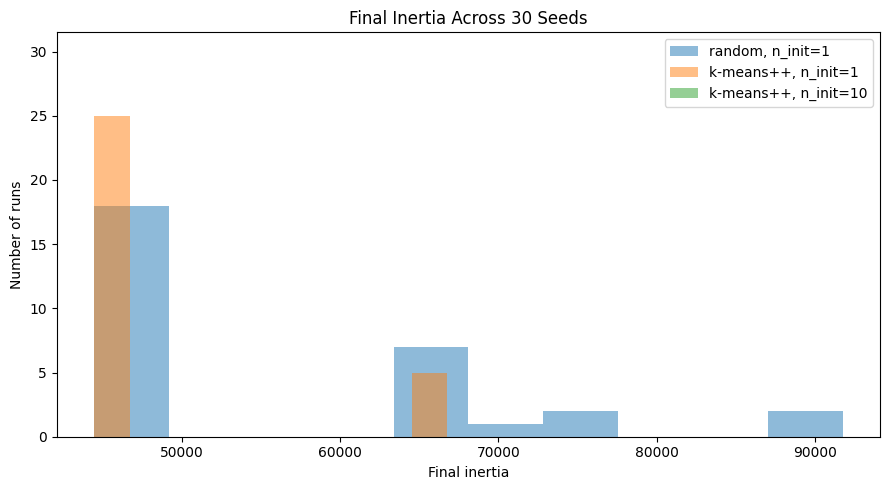

In [15]:
stability_runs = {
    "random, n_init=1": [],
    "k-means++, n_init=1": [],
    "k-means++, n_init=10": []
}

for seed in range(30):
    settings = [
        ("random, n_init=1", "random", 1),
        ("k-means++, n_init=1", "k-means++", 1),
        ("k-means++, n_init=10", "k-means++", 10)
    ]

    for name, init_method, starts in settings:
        model = KMeans(
            n_clusters=5,
            init=init_method,
            n_init=starts,
            random_state=seed
        )
        model.fit(X2)
        stability_runs[name].append(model.inertia_)

all_best = min(min(values) for values in stability_runs.values())
stability_summary = []

for name, values in stability_runs.items():
    rounded = np.round(values, 1)
    stability_summary.append({
        "Setting": name,
        "Distinct inertia values": len(np.unique(rounded)),
        "Lowest inertia": min(values),
        "Highest inertia": max(values),
        "Runs reaching best (%)": 100 * np.sum(np.isclose(values, all_best)) / len(values)
    })

stability_table = pd.DataFrame(stability_summary)
display(stability_table)

fig, ax = plt.subplots(figsize=(9, 5))
for name, values in stability_runs.items():
    ax.hist(values, alpha=0.5, bins=10, label=name)
ax.set_xlabel("Final inertia")
ax.set_ylabel("Number of runs")
ax.set_title("Final Inertia Across 30 Seeds")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** Random initialization can produce different local minima. K-means++ usually starts with more spread-out centers, while n_init=10 tries multiple initializations and keeps the best inertia. The table reports the actual results for all 30 seeds.

## Task 3.2 — Best run vs worst run

Best random inertia: 44448.45544793371 seed: 0
Worst random inertia: 91761.97619211907 seed: 13
ARI between best and worst random runs: 0.45525713010305063


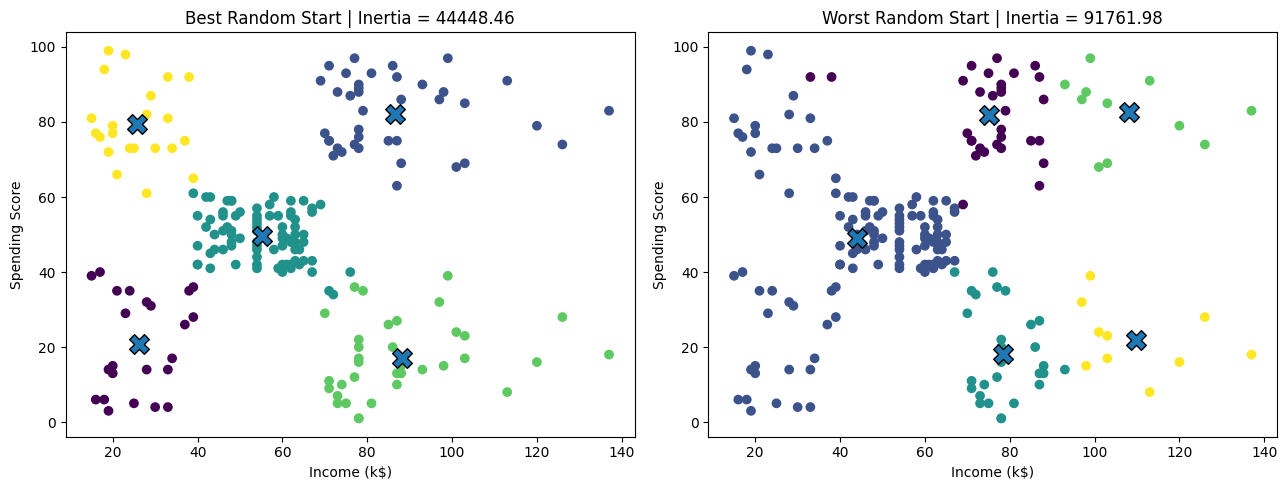

In [16]:
random_models = []

for seed in range(30):
    model = KMeans(n_clusters=5, init="random", n_init=1, random_state=seed)
    labels = model.fit_predict(X2)
    random_models.append((model.inertia_, seed, labels, model.cluster_centers_))

best_random = min(random_models, key=lambda item: item[0])
worst_random = max(random_models, key=lambda item: item[0])

print("Best random inertia:", best_random[0], "seed:", best_random[1])
print("Worst random inertia:", worst_random[0], "seed:", worst_random[1])
print("ARI between best and worst random runs:", adjusted_rand_score(best_random[2], worst_random[2]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, result, title in [
    (axes[0], best_random, "Best Random Start"),
    (axes[1], worst_random, "Worst Random Start")
]:
    ax.scatter(X2[:, 0], X2[:, 1], c=result[2])
    ax.scatter(result[3][:, 0], result[3][:, 1], marker="X", s=200, edgecolor="black")
    ax.set_xlabel("Income (k$)")
    ax.set_ylabel("Spending Score")
    ax.set_title(title + " | Inertia = " + str(round(result[0], 2)))

plt.tight_layout()
plt.show()

**Interpretation:** The best run has the lowest inertia among the 30 random starts, while the worst run has the highest. Different initial centroids can lead the assign/update process to different local minima. ARI compares the two groupings without depending on their numeric cluster labels.

In [17]:
random_distinct = stability_table.loc[stability_table["Setting"] == "random, n_init=1", "Distinct inertia values"].iloc[0]
random_best_pct = stability_table.loc[stability_table["Setting"] == "random, n_init=1", "Runs reaching best (%)"].iloc[0]
print("3(a): Random initialization produced", random_distinct, "distinct inertia values; best-inertia rate =", round(random_best_pct, 1), "%.")
print("3(b): The same data and K can give different answers because the initial centroids can be different.")
print("3(c): K-means++ chooses better-spread starting points. n_init repeats the process and keeps the lowest-inertia run.")
print("3(d): ARI is suitable because cluster numbers are arbitrary; it compares the actual grouping.")

3(a): Random initialization produced 14 distinct inertia values; best-inertia rate = 33.3 %.
3(b): The same data and K can give different answers because the initial centroids can be different.
3(c): K-means++ chooses better-spread starting points. n_init repeats the process and keeps the lowest-inertia run.
3(d): ARI is suitable because cluster numbers are arbitrary; it compares the actual grouping.


# Part 4 — Scaling: Units Decide the Clusters

## Task 4.1 — Change the unit, change the clusters

ARI raw k$ vs raw dollars: 0.48965682118947657
ARI scaled k$ vs scaled dollars: 1.0
ARI raw dollars vs scaled dollars: 0.36045266264603926


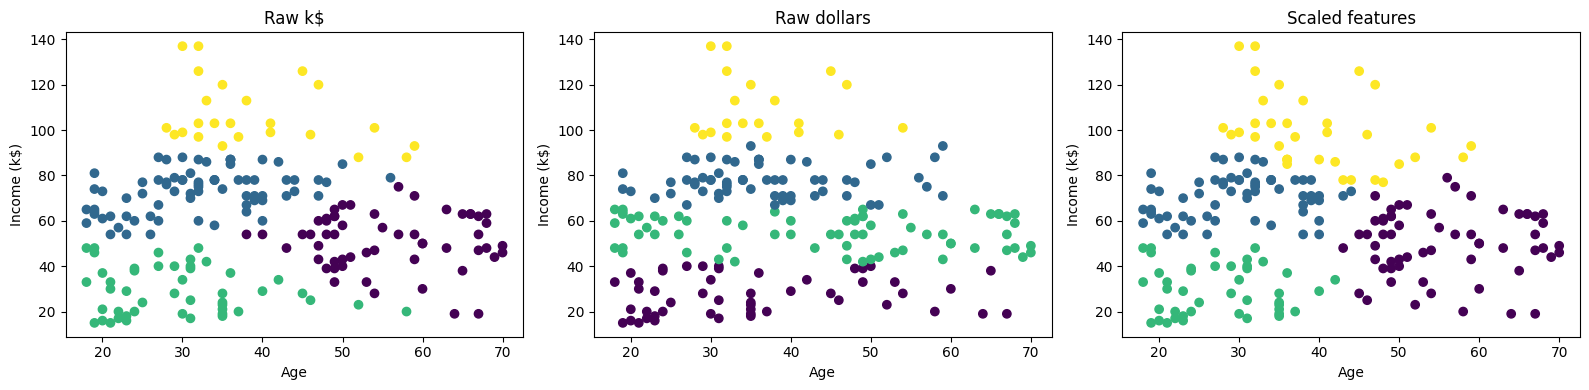

In [18]:
age_income = df[["Age", "Income"]].values
age_income_dollars = age_income.copy()
age_income_dollars[:, 1] = age_income_dollars[:, 1] * 1000

scaled_k = StandardScaler().fit_transform(age_income)
scaled_dollars = StandardScaler().fit_transform(age_income_dollars)

raw_k_model = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(age_income)
raw_dollar_model = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(age_income_dollars)
scaled_k_model = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(scaled_k)
scaled_dollar_model = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(scaled_dollars)

print("ARI raw k$ vs raw dollars:", adjusted_rand_score(raw_k_model.labels_, raw_dollar_model.labels_))
print("ARI scaled k$ vs scaled dollars:", adjusted_rand_score(scaled_k_model.labels_, scaled_dollar_model.labels_))
print("ARI raw dollars vs scaled dollars:", adjusted_rand_score(raw_dollar_model.labels_, scaled_dollar_model.labels_))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_data = [
    (raw_k_model.labels_, "Raw k$"),
    (raw_dollar_model.labels_, "Raw dollars"),
    (scaled_k_model.labels_, "Scaled features")
]

for ax, (labels, title) in zip(axes, plot_data):
    ax.scatter(df["Age"], df["Income"], c=labels)
    ax.set_xlabel("Age")
    ax.set_ylabel("Income (k$)")
    ax.set_title(title)

plt.tight_layout()
plt.show()

**Interpretation:** Changing income from thousands to dollars multiplies that feature by 1000. Without scaling, income can dominate Euclidean distance and change the clusters. StandardScaler puts both features on comparable scales, so changing the unit should not materially change the scaled grouping.

## Task 4.2 — Wine data: raw vs scaled

In [19]:
wine = load_wine()
wine_X = wine.data
wine_y = wine.target

wine_df = pd.DataFrame(wine_X, columns=wine.feature_names)
wine_std = wine_df.std()

print("Three largest standard deviations:")
display(wine_std.sort_values(ascending=False).head(3).to_frame("Standard Deviation"))
print("Smallest standard deviation:")
display(wine_std.sort_values().head(1).to_frame("Standard Deviation"))

wine_scaled = StandardScaler().fit_transform(wine_X)

wine_raw_model = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(wine_X)
wine_scaled_model = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(wine_scaled)

wine_comparison = pd.DataFrame([
    {
        "Data": "Raw",
        "ARI vs true cultivar": adjusted_rand_score(wine_y, wine_raw_model.labels_),
        "Silhouette": silhouette_score(wine_X, wine_raw_model.labels_)
    },
    {
        "Data": "Scaled",
        "ARI vs true cultivar": adjusted_rand_score(wine_y, wine_scaled_model.labels_),
        "Silhouette": silhouette_score(wine_scaled, wine_scaled_model.labels_)
    }
])
display(wine_comparison)

print("Raw cluster sizes:")
print(pd.Series(wine_raw_model.labels_).value_counts().sort_index())
print("Scaled cluster sizes:")
print(pd.Series(wine_scaled_model.labels_).value_counts().sort_index())

Three largest standard deviations:


,Standard Deviation
proline,314.907474
magnesium,14.282484
alcalinity_of_ash,3.339564


Smallest standard deviation:


,Standard Deviation
nonflavanoid_phenols,0.124453


,Data,ARI vs true cultivar,Silhouette
0,Raw,0.371114,0.571138
1,Scaled,0.897495,0.284859


Raw cluster sizes:
0    62
1    47
2    69
Name: count, dtype: int64
Scaled cluster sizes:
0    65
1    51
2    62
Name: count, dtype: int64


**Interpretation:** Raw Wine features have different units and ranges, so features with large standard deviations can dominate Euclidean distance. Scaling gives each feature a comparable standard deviation. ARI checks agreement with the known cultivar labels; those labels are used only for evaluation, not for fitting K-Means.

## Task 4.3 — Draw it

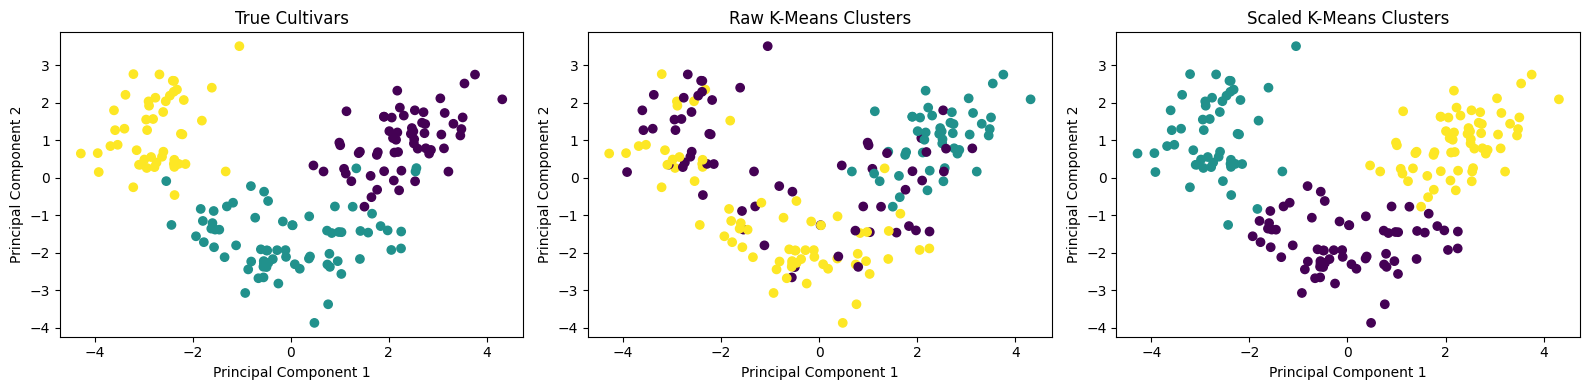

In [20]:
pca = PCA(n_components=2)
wine_2d = pca.fit_transform(wine_scaled)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
views = [
    (wine_y, "True Cultivars"),
    (wine_raw_model.labels_, "Raw K-Means Clusters"),
    (wine_scaled_model.labels_, "Scaled K-Means Clusters")
]

for ax, (labels, title) in zip(axes, views):
    ax.scatter(wine_2d[:, 0], wine_2d[:, 1], c=labels)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.set_title(title)

plt.tight_layout()
plt.show()

**Interpretation:** All three views use the same two-dimensional PCA projection of the scaled Wine data, so their visual positions are comparable. Only the coloring changes: true cultivar, raw-data clusters and scaled-data clusters.

In [21]:
largest_feature = wine_std.idxmax()
largest_std = wine_std.max()
smallest_std = wine_std.min()

print("4(a): When income is changed to dollars without scaling, its numeric values become much larger and can dominate Euclidean distance.")
print("4(b): The largest raw Wine standard deviation belongs to", largest_feature, "with standard deviation", round(largest_std, 3), "; the smallest is", round(smallest_std, 3))
print("Raw Wine ARI:", round(adjusted_rand_score(wine_y, wine_raw_model.labels_), 4))
print("Scaled Wine ARI:", round(adjusted_rand_score(wine_y, wine_scaled_model.labels_), 4))
print("4(c): Silhouette measures compactness and separation in the feature space being used; a high score does not guarantee agreement with true classes. Raw and scaled silhouette values use different distance spaces, so they are not directly fair comparisons.")
print("4(d): In a real project, I would inspect feature units and standard deviations. If features use different scales and should contribute comparably, I would scale them before distance-based clustering.")

4(a): When income is changed to dollars without scaling, its numeric values become much larger and can dominate Euclidean distance.
4(b): The largest raw Wine standard deviation belongs to proline with standard deviation 314.907 ; the smallest is 0.124
Raw Wine ARI: 0.3711
Scaled Wine ARI: 0.8975
4(c): Silhouette measures compactness and separation in the feature space being used; a high score does not guarantee agreement with true classes. Raw and scaled silhouette values use different distance spaces, so they are not directly fair comparisons.
4(d): In a real project, I would inspect feature units and standard deviations. If features use different scales and should contribute comparably, I would scale them before distance-based clustering.


# Part 5 — Outliers and Anomalies

## Task 5.1 — One extreme customer

Original cluster sizes:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
Cluster sizes with extra customer:
0    100
1      1
2     23
3     39
4     38
Name: count, dtype: int64
Original centroids sorted by income:
 [[25.72727273 79.36363636]
 [26.30434783 20.91304348]
 [55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [88.2        17.11428571]]
Centroids with outlier sorted by income:
 [[ 26.30434783  20.91304348]
 [ 48.26        56.48      ]
 [ 86.53846154  82.12820513]
 [ 87.          18.63157895]
 [400.          99.        ]]
ARI on original 200 customers: 0.7532040415286123


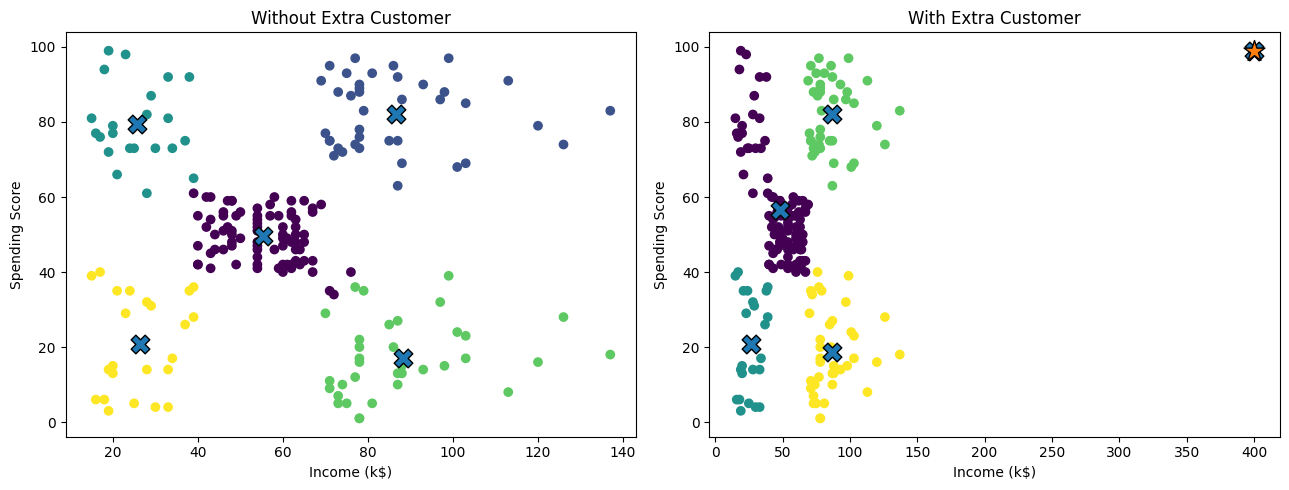

In [22]:
extra_customer = np.array([[400.0, 99.0]])
X2_with_outlier = np.vstack([X2, extra_customer])

original_model = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
outlier_model = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_with_outlier)

original_labels = original_model.labels_
outlier_labels_original = outlier_model.labels_[:len(X2)]

print("Original cluster sizes:")
print(pd.Series(original_labels).value_counts().sort_index())
print("Cluster sizes with extra customer:")
print(pd.Series(outlier_model.labels_).value_counts().sort_index())
print("Original centroids sorted by income:\n", original_model.cluster_centers_[np.argsort(original_model.cluster_centers_[:, 0])])
print("Centroids with outlier sorted by income:\n", outlier_model.cluster_centers_[np.argsort(outlier_model.cluster_centers_[:, 0])])
print("ARI on original 200 customers:", adjusted_rand_score(original_labels, outlier_labels_original))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X2[:, 0], X2[:, 1], c=original_labels)
axes[0].scatter(original_model.cluster_centers_[:, 0], original_model.cluster_centers_[:, 1], marker="X", s=180, edgecolor="black")
axes[0].set_title("Without Extra Customer")
axes[1].scatter(X2_with_outlier[:, 0], X2_with_outlier[:, 1], c=outlier_model.labels_)
axes[1].scatter(outlier_model.cluster_centers_[:, 0], outlier_model.cluster_centers_[:, 1], marker="X", s=180, edgecolor="black")
axes[1].scatter(400, 99, marker="*", s=250, edgecolor="black")
axes[1].set_title("With Extra Customer")
for ax in axes:
    ax.set_xlabel("Income (k$)")
    ax.set_ylabel("Spending Score")
plt.tight_layout()
plt.show()

**Interpretation:** The extra customer is far from the main customer population. Because K-Means uses squared distances and means, an extreme point can pull a centroid and change the assignments of real customers. The ARI quantifies how much the original 200-customer grouping changed.

## Task 5.2 — Catch it and repair

In [23]:
real_distances = original_model.transform(X2).min(axis=1)
extra_distance = original_model.transform(extra_customer).min()

distance_limit = real_distances.mean() + 3 * real_distances.std()
real_flagged = real_distances > distance_limit
extra_flagged = extra_distance > distance_limit

print("Mean real-customer distance:", real_distances.mean())
print("Standard deviation:", real_distances.std())
print("Mean + 3 std threshold:", distance_limit)
print("Real customers flagged:", int(real_flagged.sum()))
print("Extra customer distance:", extra_distance)
print("Is extra customer flagged?", bool(extra_flagged))

distance_table = df[["CustomerID", "Age", "Income", "Spending"]].copy()
distance_table["Cluster"] = original_labels
distance_table["Distance"] = real_distances
distance_table["Flagged"] = real_flagged

print("Five real customers farthest from their centroid:")
display(distance_table.sort_values("Distance", ascending=False).head(5))

clean_X2 = X2[~real_flagged]
clean_model = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(clean_X2)
repaired_labels = clean_model.predict(X2)

print("Cluster sizes after removing flagged points and refitting:")
print(pd.Series(clean_model.labels_).value_counts().sort_index())
print("ARI of repaired assignments vs original model on 200 customers:",
      adjusted_rand_score(original_labels, repaired_labels))

Mean real-customer distance: 13.020126350791761
Standard deviation: 7.260756644392302
Mean + 3 std threshold: 34.80239628396867
Real customers flagged: 4
Extra customer distance: 313.9152649312717
Is extra customer flagged? True
Five real customers farthest from their centroid:


,CustomerID,Age,Income,Spending,Cluster,Distance,Flagged
199,200,30,137,83,1,50.469069,True
198,199,32,137,18,3,48.808037,True
197,198,32,126,74,1,40.289958,True
196,197,45,126,28,3,39.336227,True
195,196,35,120,79,1,33.607443,False


Cluster sizes after removing flagged points and refitting:
0    80
1    34
2    23
3    37
4    22
Name: count, dtype: int64
ARI of repaired assignments vs original model on 200 customers: 0.9847169139719528


**Interpretation:** The mean + 3 standard deviations rule flags customers whose distance to their nearest centroid is unusually large. The extra customer's flag status and the number of real customers flagged are printed above. Removing flagged points can improve a model when they are genuine errors, but deleting valid unusual customers can remove useful business information.

In [24]:
print("5(a): Compare the cluster sizes, centroids and ARI from Task 5.1 to see which groups were affected by the extra customer.")
print("5(b): The extra customer's distance is", round(float(extra_distance), 3), "and the threshold is", round(float(distance_limit), 3), ". Flagged:", bool(extra_flagged))
print("5(c): Two ways to handle outliers are to investigate/correct data errors or use a method less sensitive to extreme values. Deleting valid unusual customers can remove important information.")

5(a): Compare the cluster sizes, centroids and ARI from Task 5.1 to see which groups were affected by the extra customer.
5(b): The extra customer's distance is 313.915 and the threshold is 34.802 . Flagged: True
5(c): Two ways to handle outliers are to investigate/correct data errors or use a method less sensitive to extreme values. Deleting valid unusual customers can remove important information.


# Part 6 — From Clusters to Customer Segments

## Task 6.1 — Profile and name the segments

In [25]:
segment_model = KMeans(n_clusters=5, n_init=10, random_state=SEED)
df["Cluster"] = segment_model.fit_predict(X2)

profile = df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Spending=("Spending", "mean"),
    Female_Percent=("Gender", lambda values: 100 * (values == "Female").mean())
).sort_values("Mean_Income")

display(profile.round(2))

def income_level(value):
    if value < 40:
        return "Low"
    if value >= 70:
        return "High"
    return "Mid"

def spending_level(value):
    if value < 35:
        return "Low"
    if value >= 65:
        return "High"
    return "Mid"

cluster_names = {}

for cluster, row in profile.iterrows():
    cluster_names[cluster] = income_level(row["Mean_Income"]) + " Income / " + spending_level(row["Mean_Spending"]) + " Spending"

df["Segment"] = df["Cluster"].map(cluster_names)

print("Segment names:")
print(cluster_names)
print("Segment sizes:")
display(df["Segment"].value_counts().to_frame("Customers"))

,Customers,Mean_Age,Mean_Income,Mean_Spending,Female_Percent
Cluster,,,,,
2,22,25.27,25.73,79.36,59.09
4,23,45.22,26.30,20.91,60.87
0,81,42.72,55.30,49.52,59.26
1,39,32.69,86.54,82.13,53.85
3,35,41.11,88.20,17.11,45.71


Segment names:
{2: 'Low Income / High Spending', 4: 'Low Income / Low Spending', 0: 'Mid Income / Mid Spending', 1: 'High Income / High Spending', 3: 'High Income / Low Spending'}
Segment sizes:


,Customers
Segment,
Mid Income / Mid Spending,81
High Income / High Spending,39
High Income / Low Spending,35
Low Income / Low Spending,23
Low Income / High Spending,22


**Interpretation:** The profile table describes each cluster using customer count, average age, average income, average spending score and female percentage. Segment names are generated using the manual's income and spending thresholds, making the numeric cluster labels easier for a manager to understand.

## Task 6.2 — Does Gender matter? Does Age matter?

In [26]:
gender_by_segment = pd.crosstab(df["Segment"], df["Gender"], normalize="index") * 100
print("Gender percentages within each segment:")
display(gender_by_segment.round(2))
print("Overall female percentage:", round(100 * (df["Gender"] == "Female").mean(), 2))

age_income_spending = df[["Age", "Income", "Spending"]].values
scaled_three = StandardScaler().fit_transform(age_income_spending)

three_feature_silhouette = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = model.fit_predict(scaled_three)
    three_feature_silhouette.append({
        "K": k,
        "Average Silhouette": silhouette_score(scaled_three, labels)
    })

three_feature_table = pd.DataFrame(three_feature_silhouette)
display(three_feature_table)
best_three_k = int(three_feature_table.loc[three_feature_table["Average Silhouette"].idxmax(), "K"])
print("Best K by silhouette for scaled Age, Income and Spending:", best_three_k)

Gender percentages within each segment:


Gender,Female,Male
Segment,,
High Income / High Spending,53.85,46.15
High Income / Low Spending,45.71,54.29
Low Income / High Spending,59.09,40.91
Low Income / Low Spending,60.87,39.13
Mid Income / Mid Spending,59.26,40.74


Overall female percentage: 56.0


,K,Average Silhouette
0,2,0.335472
1,3,0.357793
2,4,0.403958
3,5,0.416643
4,6,0.428417
5,7,0.417232
6,8,0.408207


Best K by silhouette for scaled Age, Income and Spending: 6


**Interpretation:** Gender percentages show whether the segments have different gender compositions. The three-feature silhouette table measures clustering after Age, Income and Spending are scaled together. Silhouette values from different feature sets should not be treated as directly comparable.

## Task 6.3 — A three-feature alternative

In [27]:
three_feature_model = KMeans(n_clusters=best_three_k, n_init=10, random_state=SEED)
three_feature_labels = three_feature_model.fit_predict(scaled_three)

three_profile_data = df[["Age", "Income", "Spending"]].copy()
three_profile_data["Cluster"] = three_feature_labels

three_profile = three_profile_data.groupby("Cluster").agg(
    Customers=("Age", "count"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Income", "mean"),
    Mean_Spending=("Spending", "mean")
).sort_values("Mean_Age")

display(three_profile.round(2))
print("ARI between 3-feature segmentation and 2-feature K=5 segmentation:",
      adjusted_rand_score(df["Cluster"], three_feature_labels))

,Customers,Mean_Age,Mean_Income,Mean_Spending
Cluster,,,,
4,23,25.00,25.26,77.61
1,39,26.79,57.10,48.13
3,39,32.69,86.54,82.13
2,33,41.94,88.94,16.97
5,21,45.52,26.29,19.38
0,45,56.33,54.27,49.07


ARI between 3-feature segmentation and 2-feature K=5 segmentation: 0.7002329184122666


**Interpretation:** The three-feature alternative includes Age as well as Income and Spending. The profile table shows how its groups differ, while ARI measures agreement with the original two-feature, five-cluster segmentation.

In [28]:
print("6(a): Suggested business actions based on the profile table:")
for cluster, row in profile.iterrows():
    name = cluster_names[cluster]
    if "High Income / High Spending" in name:
        action = "Offer loyalty rewards and premium services."
    elif "High Income / Low Spending" in name:
        action = "Send targeted promotions to encourage spending."
    elif "Low Income / High Spending" in name:
        action = "Offer value bundles and reward repeat visits."
    elif "Low Income / Low Spending" in name:
        action = "Use low-cost introductory offers."
    else:
        action = "Recommend products based on purchase interests."
    print(name, "—", int(row["Customers"]), "customers —", action)

most_valuable = profile["Mean_Spending"].idxmax()
biggest_opportunity = profile["Customers"].idxmax()
print("6(b): Highest average spending cluster:", most_valuable, "| Biggest segment by size:", biggest_opportunity)
print("6(c): Use the gender percentages above to decide whether Gender separates the segments meaningfully.")
print("6(d): Adding Age changes the feature space and may change the grouping. Choose the segmentation whose profiles are more useful and interpretable for the business, not simply the one with a numerically larger silhouette.")

6(a): Suggested business actions based on the profile table:
Low Income / High Spending — 22 customers — Offer value bundles and reward repeat visits.
Low Income / Low Spending — 23 customers — Use low-cost introductory offers.
Mid Income / Mid Spending — 81 customers — Recommend products based on purchase interests.
High Income / High Spending — 39 customers — Offer loyalty rewards and premium services.
High Income / Low Spending — 35 customers — Send targeted promotions to encourage spending.
6(b): Highest average spending cluster: 1 | Biggest segment by size: 0
6(c): Use the gender percentages above to decide whether Gender separates the segments meaningfully.
6(d): Adding Age changes the feature space and may change the grouping. Choose the segmentation whose profiles are more useful and interpretable for the business, not simply the one with a numerically larger silhouette.


# Part 7 — Final Output and Wrap-Up

## Task 7.1 — Save the segments

In [29]:
final_columns = ["CustomerID", "Age", "Gender", "Income", "Spending", "Cluster", "Segment"]
customer_segments = df[final_columns].copy()
customer_segments.to_csv("customer_segments.csv", index=False)

print("Saved customer_segments.csv")
print("Number of customers:", len(customer_segments))
print("Customers per segment:")
display(customer_segments["Segment"].value_counts().to_frame("Customers"))

Saved customer_segments.csv
Number of customers: 200
Customers per segment:


,Customers
Segment,
Mid Income / Mid Spending,81
High Income / High Spending,39
High Income / Low Spending,35
Low Income / Low Spending,23
Low Income / High Spending,22


## Executive Summary

The Mall Customers dataset was grouped using K-Means with Income and Spending as the main features. The selected two-feature segmentation uses K = 5, as required for the customer profiling tasks in the lab. The elbow curve and silhouette results provide evidence for evaluating this choice. The five segments are named using their average income and spending levels, and each segment is paired with a suggested marketing action. StandardScaler was used in the scaling experiments to prevent features with larger numeric units from dominating distance calculations. An extreme customer was added to measure its effect, then a mean + 3 standard deviations distance rule was used to flag unusual records. One limitation is that K-Means is sensitive to initialization, outliers and the chosen feature set, and there is no true target label for the Mall Customers data.

In [30]:
print("7(a): The most surprising result is the change in clustering when feature units or scaling change; review the ARI values in Part 4.")
print("7(b): A useful next step would be to test another clustering algorithm or validate the segments with additional customer behavior data.")
print("Final files: customer_segments.csv")
print("Final customer count:", len(customer_segments))

7(a): The most surprising result is the change in clustering when feature units or scaling change; review the ARI values in Part 4.
7(b): A useful next step would be to test another clustering algorithm or validate the segments with additional customer behavior data.
Final files: customer_segments.csv
Final customer count: 200
